# SmartServe — Exploratory Data Analysis

## Business Objective

Analyze historical sales and operational data to identify
patterns, business opportunities, and operational inefficiencies.

## Analysis Sections

1. Sales Performance Analysis
2. Store Performance Analysis
3. Product Performance Analysis
4. Customer Behavior Analysis
5. Inventory and Preparation Analysis
6. Food Waste Analysis
7. Business Insights and Recommendations

### Import libraries and load datasets

In [1]:

import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Add project root to Python path
PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

# Import project data loader
from src.data_loader import load_all_data

# Load datasets
data = load_all_data()

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# Create convenient DataFrame references
sales = data["fact_sales"].copy()
dates = data["dim_date"].copy()
stores = data["dim_store"].copy()
products = data["dim_product"].copy()
customers = data["dim_customer"].copy()
preparation = data["fact_preparation"].copy()
inventory = data["fact_inventory"].copy()
waste = data["fact_waste"].copy()

print("SMARTSERVE EDA ENVIRONMENT READY")
print("=" * 50)
print(f"Datasets loaded: {len(data)}")
print(f"Sales records: {len(sales):,}")
print(f"Stores: {len(stores):,}")
print(f"Products: {len(products):,}")
print(f"Customers: {len(customers):,}")


2026-11-07 12:51:15,565 | INFO | src.data_loader | Loading data file: D:\Data Analysis Projects\SmartServe-Food-Intelligence\data\raw\dim_date.csv
2026-11-07 12:51:15,593 | INFO | src.data_loader | Loading data file: D:\Data Analysis Projects\SmartServe-Food-Intelligence\data\raw\dim_store.csv
2026-11-07 12:51:15,683 | INFO | src.data_loader | Loading data file: D:\Data Analysis Projects\SmartServe-Food-Intelligence\data\raw\dim_product.csv
2026-11-07 12:51:15,700 | INFO | src.data_loader | Loading data file: D:\Data Analysis Projects\SmartServe-Food-Intelligence\data\raw\dim_customer.csv
2026-11-07 12:51:15,729 | INFO | src.data_loader | Loading data file: D:\Data Analysis Projects\SmartServe-Food-Intelligence\data\raw\dim_promotion.csv
2026-11-07 12:51:15,755 | INFO | src.data_loader | Loading data file: D:\Data Analysis Projects\SmartServe-Food-Intelligence\data\raw\dim_holiday.csv
2026-11-07 12:51:15,764 | INFO | src.data_loader | Loading data file: D:\Data Analysis Projects\SmartS

SMARTSERVE EDA ENVIRONMENT READY
Datasets loaded: 11
Sales records: 122,318
Stores: 5
Products: 20
Customers: 1,000


In [2]:

# Convert date columns

dates["full_date"] = pd.to_datetime(dates["full_date"])

stores["opening_date"] = pd.to_datetime(stores["opening_date"])
customers["signup_date"] = pd.to_datetime(customers["signup_date"])

sales["date_id"] = sales["date_id"].astype(int)
dates["date_id"] = dates["date_id"].astype(int)

# Attach actual dates to sales records
sales = sales.merge(
    dates[["date_id", "full_date", "year", "month", "month_name",
           "day_name", "is_weekend", "is_holiday", "season"]],
    on="date_id",
    how="left"
)

print("Date conversion completed.")
print("Sales date range:", sales["full_date"].min(), "to", sales["full_date"].max())


Date conversion completed.
Sales date range: 2025-01-01 00:00:00 to 2025-03-31 00:00:00


In [3]:

# Overall Sales Performance KPIs

total_revenue = sales["net_sales"].sum()

total_orders = sales["order_id"].nunique()

total_units_sold = sales["quantity"].sum()

average_order_value = total_revenue / total_orders if total_orders else 0

total_profit = sales["profit_amount"].sum()

total_cost = sales["cost_amount"].sum()

# Create KPI summary
sales_kpis = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Orders",
        "Total Units Sold",
        "Average Order Value",
        "Total Cost",
        "Total Profit"
    ],
    "Value": [
        total_revenue,
        total_orders,
        total_units_sold,
        average_order_value,
        total_cost,
        total_profit
    ]
})

display(
    sales_kpis.style.format({
        "Value": "{:,.2f}"
    })
)


,KPI,Value
0,Total Revenue,"49,384,617.90"
1,Total Orders,"122,318.00"
2,Total Units Sold,"296,663.00"
3,Average Order Value,403.74
4,Total Cost,"23,898,605.00"
5,Total Profit,"25,486,012.90"


In [4]:

# Additional sales performance metrics

profit_margin = (
    total_profit / total_revenue * 100
    if total_revenue else 0
)

average_units_per_order = (
    total_units_sold / total_orders
    if total_orders else 0
)

average_daily_revenue = (
    total_revenue / sales["full_date"].nunique()
)

print("ADDITIONAL SALES METRICS")
print("=" * 55)

print(f"Profit Margin: {profit_margin:.2f}%")
print(f"Average Units per Order: {average_units_per_order:.2f}")
print(f"Average Daily Revenue: {average_daily_revenue:,.2f}")


ADDITIONAL SALES METRICS
Profit Margin: 51.61%
Average Units per Order: 2.43
Average Daily Revenue: 548,717.98


## Overall Sales Performance — Initial Findings

1. Total revenue: 49,384,617.90
2. Total orders: 122,318.00
3. Total units sold: 296,663.00
4. Average order value: 403.74
5. Total profit: 23,898,605.00
6. Profit margin: 25,486,012.90

### Business Interpretation

These KPIs establish the baseline performance of SmartServe.
They will help us compare stores, products, and customer segments
in subsequent analyses.

### Overall Sales Performance — Key Findings

1. **Revenue:** The business generated 49,384,617.90 in net sales during the 90-day analysis period.

2. **Profitability:** Total profit was 25,486,012.90, representing a profit margin of 51.61%.

3. **Customer spending:** Average Order Value (AOV) was 403.74 per order.

4. **Order volume:** The business recorded 122,318 orders and sold 296,663 units.

5. **Order size:** Customers purchased an average of 2.43 units per order.

6. **Daily performance:** Average daily revenue was 548,717.98.

**Business implication:** The business demonstrates strong generated sales and profitability. Further analysis should identify which dates, stores, and products contribute most to revenue and profit.

**Note:** These findings describe the synthetic dataset, not actual café performance.

In [5]:
# Daily sales aggregation

daily_sales = (
    sales.groupby("full_date")
    .agg(
        total_revenue=("net_sales", "sum"),
        total_orders=("order_id", "nunique"),
        total_units=("quantity", "sum"),
        total_profit=("profit_amount", "sum")
    )
    .reset_index()
)

daily_sales.head()

,full_date,total_revenue,total_orders,total_units,total_profit
0,2025-01-01,544995.0,1253,3137,282825.0
1,2025-01-02,485865.0,1216,2922,256335.0
2,2025-01-03,524430.0,1267,3075,274025.0
3,2025-01-04,608193.0,1480,3600,318538.0
4,2025-01-05,615825.0,1490,3692,324280.0


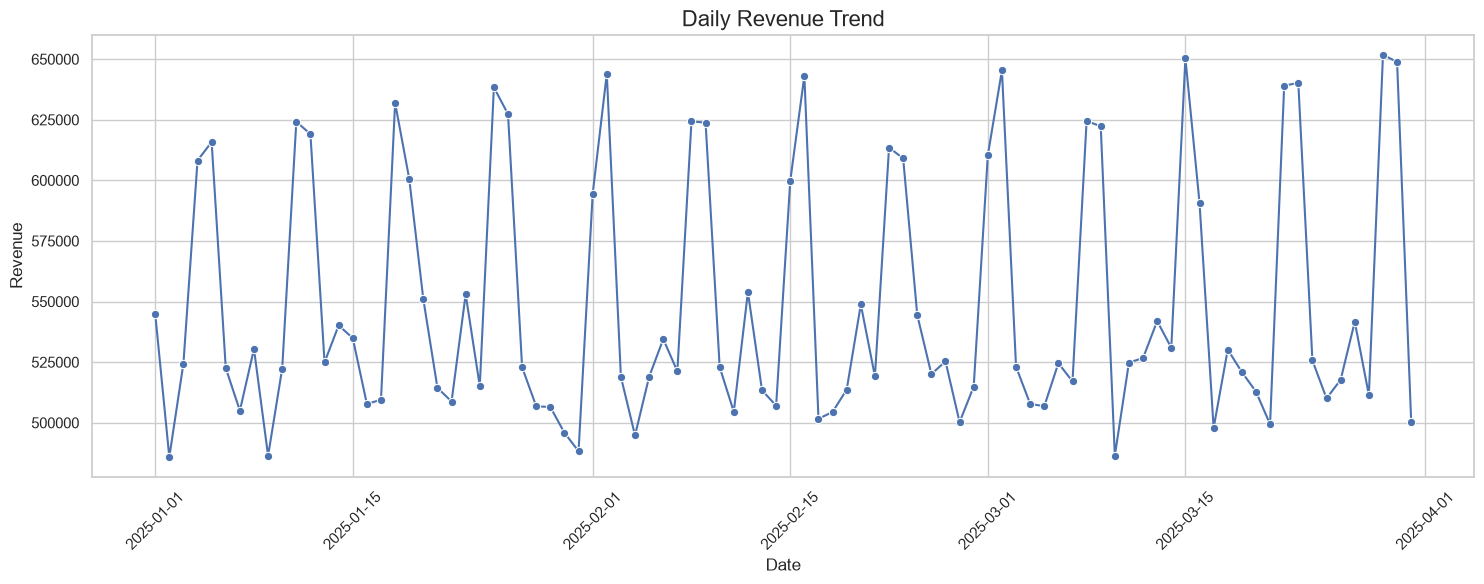

In [6]:
plt.figure(figsize=(15, 6))

sns.lineplot(
    data=daily_sales,
    x="full_date",
    y="total_revenue",
    marker="o"
)

plt.title("Daily Revenue Trend", fontsize=16)
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [7]:
# Revenue and orders by day of the week

weekday_sales = (
    sales.groupby("day_name")
    .agg(
        total_revenue=("net_sales", "sum"),
        total_orders=("order_id", "nunique"),
        total_units=("quantity", "sum")
    )
    .reset_index()
)

# Arrange days in calendar order
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_sales["day_name"] = pd.Categorical(
    weekday_sales["day_name"],
    categories=weekday_order,
    ordered=True
)

weekday_sales = weekday_sales.sort_values("day_name")

display(weekday_sales)

,day_name,total_revenue,total_orders,total_units
1,Monday,6742559.4,16632,40328
5,Tuesday,6163206.6,15325,37062
6,Wednesday,6809691.7,16847,40837
4,Thursday,6746812.2,16801,40587
0,Friday,6680866.8,16621,40127
2,Saturday,8110954.4,20100,48786
3,Sunday,8130526.8,19992,48936


2026-11-07 12:58:13,830 | INFO | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-11-07 12:58:13,865 | INFO | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


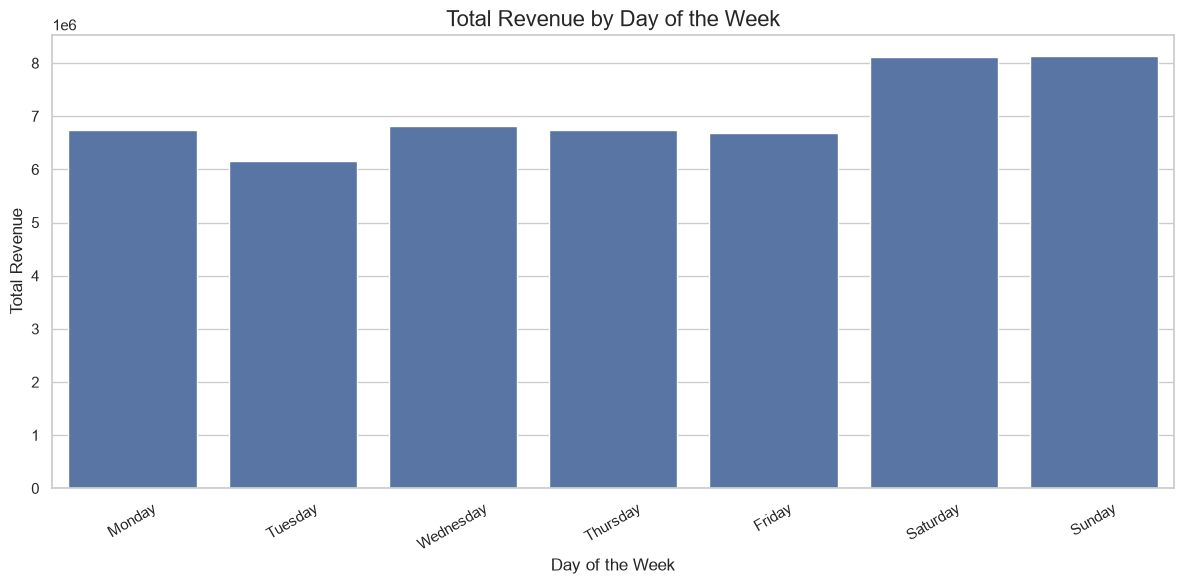

In [8]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=weekday_sales,
    x="day_name",
    y="total_revenue"
)

plt.title("Total Revenue by Day of the Week", fontsize=16)
plt.xlabel("Day of the Week")
plt.ylabel("Total Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [9]:
monthly_sales = (
    sales.groupby(["year", "month", "month_name"])
    .agg(
        total_revenue=("net_sales", "sum"),
        total_orders=("order_id", "nunique"),
        total_units=("quantity", "sum"),
        total_profit=("profit_amount", "sum")
    )
    .reset_index()
    .sort_values(["year", "month"])
)

display(monthly_sales)

,year,month,month_name,total_revenue,total_orders,total_units,total_profit
0,2025,1,January,16867603.0,41395,100714,8752698.0
1,2025,2,February,15335024.2,37956,91792,7921839.2
2,2025,3,March,17181990.7,42967,104157,8811475.7


2026-11-07 12:58:49,989 | INFO | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-11-07 12:58:50,009 | INFO | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


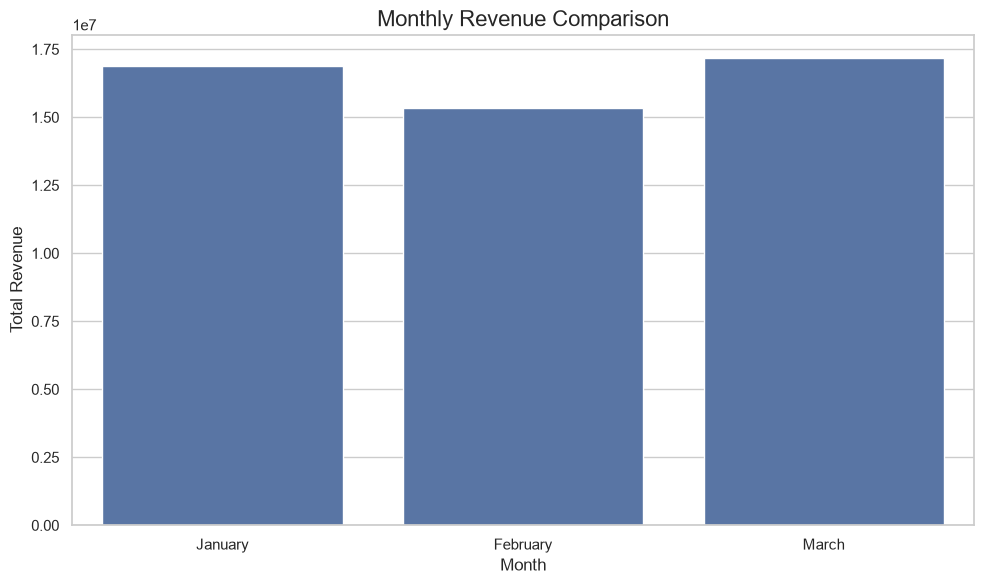

In [10]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=monthly_sales,
    x="month_name",
    y="total_revenue"
)

plt.title("Monthly Revenue Comparison", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()

In [11]:
# Merge sales data with store dimension

store_sales = sales.merge(
    stores,
    on="store_id",
    how="left"
)

print("Store sales dataset created.")
print("Records:", f"{len(store_sales):,}")

store_sales.head()

Store sales dataset created.
Records: 122,318


,sales_id,order_id,date_id,store_id,customer_id,product_id,promotion_id,quantity,unit_price,discount_amount,...,is_holiday,season,store_name,city,area,store_type,opening_date,seating_capacity,average_daily_customers,manager_region
0,SAL00000001,ORD00000001,20250101,ST001,CUS00522,PRD001,PROMO007,3,120.0,36.0,...,True,Winter,SmartServe Dhaka 1,Dhaka,Downtown,Flagship,2022-01-01,40,180,Central
1,SAL00000002,ORD00000002,20250101,ST001,CUS00094,PRD001,PROMO007,2,120.0,24.0,...,True,Winter,SmartServe Dhaka 1,Dhaka,Downtown,Flagship,2022-01-01,40,180,Central
2,SAL00000003,ORD00000003,20250101,ST001,CUS00613,PRD001,PROMO007,1,120.0,12.0,...,True,Winter,SmartServe Dhaka 1,Dhaka,Downtown,Flagship,2022-01-01,40,180,Central
3,SAL00000004,ORD00000004,20250101,ST001,CUS00556,PRD001,PROMO007,1,120.0,12.0,...,True,Winter,SmartServe Dhaka 1,Dhaka,Downtown,Flagship,2022-01-01,40,180,Central
4,SAL00000005,ORD00000005,20250101,ST001,CUS00026,PRD001,PROMO007,4,120.0,48.0,...,True,Winter,SmartServe Dhaka 1,Dhaka,Downtown,Flagship,2022-01-01,40,180,Central


In [12]:
store_performance = (
    store_sales.groupby(
        ["store_id", "city", "area", "store_type"]
    )
    .agg(
        total_revenue=("net_sales", "sum"),
        total_orders=("order_id", "nunique"),
        total_units=("quantity", "sum"),
        total_cost=("cost_amount", "sum"),
        total_profit=("profit_amount", "sum")
    )
    .reset_index()
)

store_performance["profit_margin"] = (
    store_performance["total_profit"]
    / store_performance["total_revenue"] * 100
)

store_performance = store_performance.sort_values(
    "total_revenue",
    ascending=False
)

display(
    store_performance.style.format({
        "total_revenue": "{:,.2f}",
        "total_cost": "{:,.2f}",
        "total_profit": "{:,.2f}",
        "profit_margin": "{:.2f}%"
    })
)

,store_id,city,area,store_type,total_revenue,total_orders,total_units,total_cost,total_profit,profit_margin
3,ST004,Rajshahi,Business District,Flagship,"12,131,339.10",29799,72734,"5,876,075.00","6,255,264.10",51.56%
0,ST001,Dhaka,Downtown,Flagship,"11,967,970.00",29631,71927,"5,789,060.00","6,178,910.00",51.63%
1,ST002,Chattogram,Shopping Mall,Standard,"9,214,085.40",22857,55357,"4,462,275.00","4,751,810.40",51.57%
4,ST005,Khulna,Residential Area,Standard,"9,184,137.80",22659,55222,"4,442,590.00","4,741,547.80",51.63%
2,ST003,Sylhet,University Area,Express,"6,887,085.60",17372,41423,"3,328,605.00","3,558,480.60",51.67%


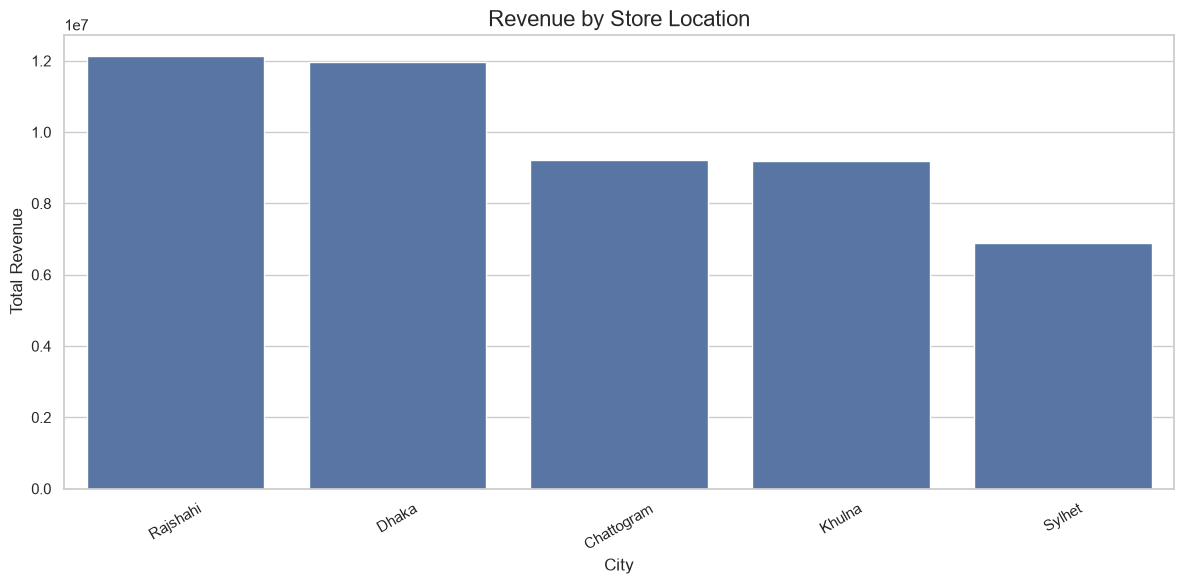

In [13]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=store_performance,
    x="city",
    y="total_revenue"
)

plt.title("Revenue by Store Location", fontsize=16)
plt.xlabel("City")
plt.ylabel("Total Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

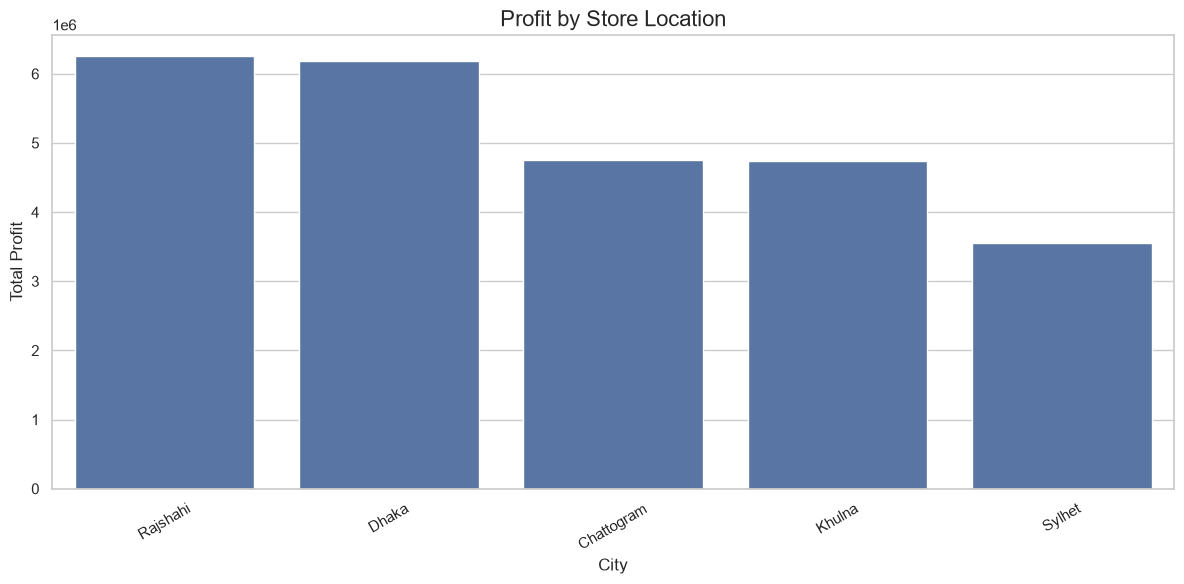

In [14]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=store_performance,
    x="city",
    y="total_profit"
)

plt.title("Profit by Store Location", fontsize=16)
plt.xlabel("City")
plt.ylabel("Total Profit")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [15]:
best_revenue_store = store_performance.loc[
    store_performance["total_revenue"].idxmax()
]

best_profit_store = store_performance.loc[
    store_performance["total_profit"].idxmax()
]

best_margin_store = store_performance.loc[
    store_performance["profit_margin"].idxmax()
]

print("STORE PERFORMANCE HIGHLIGHTS")
print("=" * 55)

print(
    f"Highest Revenue: {best_revenue_store['city']} "
    f"({best_revenue_store['total_revenue']:,.2f})"
)

print(
    f"Highest Profit: {best_profit_store['city']} "
    f"({best_profit_store['total_profit']:,.2f})"
)

print(
    f"Highest Profit Margin: {best_margin_store['city']} "
    f"({best_margin_store['profit_margin']:.2f}%)"
)

STORE PERFORMANCE HIGHLIGHTS
Highest Revenue: Rajshahi (12,131,339.10)
Highest Profit: Rajshahi (6,255,264.10)
Highest Profit Margin: Sylhet (51.67%)


In [16]:
# Merge sales data with product dimension

product_sales = sales.merge(
    products,
    on="product_id",
    how="left"
)

print("Product sales dataset created.")
print("Records:", f"{len(product_sales):,}")

product_sales.head()

Product sales dataset created.
Records: 122,318


,sales_id,order_id,date_id,store_id,customer_id,product_id,promotion_id,quantity,unit_price,discount_amount,...,season,product_name,category,subcategory,size,unit_cost,selling_price,shelf_life_hours,preparation_time,active_flag
0,SAL00000001,ORD00000001,20250101,ST001,CUS00522,PRD001,PROMO007,3,120.0,36.0,...,Winter,Americano,Beverage,Coffee,Regular,45,120,4,3,True
1,SAL00000002,ORD00000002,20250101,ST001,CUS00094,PRD001,PROMO007,2,120.0,24.0,...,Winter,Americano,Beverage,Coffee,Regular,45,120,4,3,True
2,SAL00000003,ORD00000003,20250101,ST001,CUS00613,PRD001,PROMO007,1,120.0,12.0,...,Winter,Americano,Beverage,Coffee,Regular,45,120,4,3,True
3,SAL00000004,ORD00000004,20250101,ST001,CUS00556,PRD001,PROMO007,1,120.0,12.0,...,Winter,Americano,Beverage,Coffee,Regular,45,120,4,3,True
4,SAL00000005,ORD00000005,20250101,ST001,CUS00026,PRD001,PROMO007,4,120.0,48.0,...,Winter,Americano,Beverage,Coffee,Regular,45,120,4,3,True


In [17]:
product_performance = (
    product_sales.groupby(
        ["product_id", "product_name", "category", "subcategory"]
    )
    .agg(
        total_revenue=("net_sales", "sum"),
        total_units=("quantity", "sum"),
        total_orders=("order_id", "nunique"),
        total_cost=("cost_amount", "sum"),
        total_profit=("profit_amount", "sum")
    )
    .reset_index()
)

product_performance["profit_margin"] = (
    product_performance["total_profit"]
    / product_performance["total_revenue"] * 100
)

product_performance = product_performance.sort_values(
    "total_revenue",
    ascending=False
)

display(
    product_performance.style.format({
        "total_revenue": "{:,.2f}",
        "total_cost": "{:,.2f}",
        "total_profit": "{:,.2f}",
        "profit_margin": "{:.2f}%"
    })
)

,product_id,product_name,category,subcategory,total_revenue,total_units,total_orders,total_cost,total_profit,profit_margin
11,PRD012,Beef Burger,Food,Burger,"4,209,523.50",13698,5632,"2,465,640.00","1,743,883.50",41.43%
12,PRD013,Chicken Burger,Food,Burger,"3,851,523.20",13720,5724,"2,195,200.00","1,656,323.20",43.00%
3,PRD004,Mocha,Beverage,Coffee,"3,778,226.00",22308,9085,"1,784,640.00","1,993,586.00",52.77%
2,PRD003,Latte,Beverage,Coffee,"3,303,159.50",21820,8962,"1,527,400.00","1,775,759.50",53.76%
1,PRD002,Cappuccino,Beverage,Coffee,"3,222,704.00",22606,9234,"1,469,390.00","1,753,314.00",54.41%
6,PRD007,Iced Latte,Beverage,Cold Drinks,"3,167,510.00",17748,7299,"1,419,840.00","1,747,670.00",55.17%
10,PRD011,Chicken Sandwich,Food,Sandwich,"2,915,530.80",11877,4928,"1,662,780.00","1,252,750.80",42.97%
5,PRD006,Iced Coffee,Beverage,Cold Drinks,"2,902,095.00",18106,7406,"1,267,420.00","1,634,675.00",56.33%
7,PRD008,Lemonade,Beverage,Cold Drinks,"2,471,542.50",18525,7588,"1,018,875.00","1,452,667.50",58.78%
13,PRD014,Veggie Sandwich,Food,Sandwich,"2,439,564.00",11606,4835,"1,276,660.00","1,162,904.00",47.67%


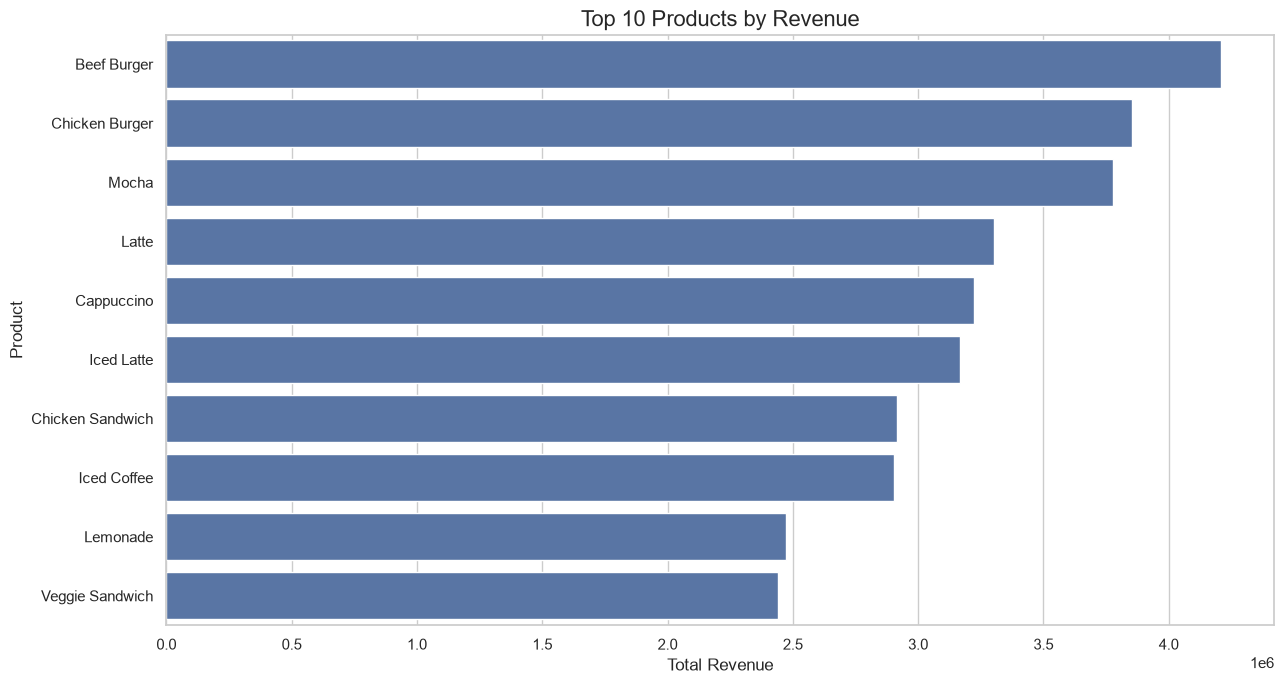

In [18]:
top_10_revenue = product_performance.nlargest(
    10, "total_revenue"
)

plt.figure(figsize=(13, 7))

sns.barplot(
    data=top_10_revenue,
    x="total_revenue",
    y="product_name"
)

plt.title("Top 10 Products by Revenue", fontsize=16)
plt.xlabel("Total Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

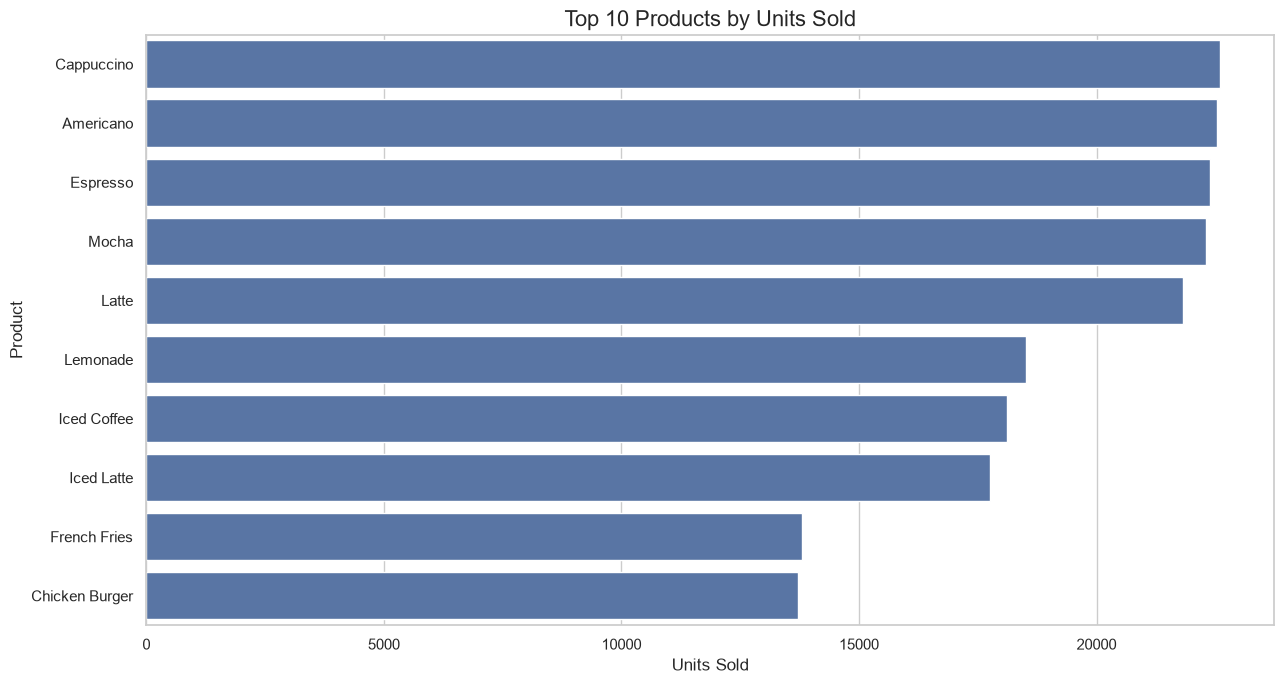

In [19]:
top_10_units = product_performance.nlargest(
    10, "total_units"
)

plt.figure(figsize=(13, 7))

sns.barplot(
    data=top_10_units,
    x="total_units",
    y="product_name"
)

plt.title("Top 10 Products by Units Sold", fontsize=16)
plt.xlabel("Units Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

,category,total_revenue,total_units,total_profit
0,Beverage,27538960.5,187501,15166660.5
2,Food,15353203.9,64709,6855403.9
1,Dessert,6492453.5,44453,3463948.5


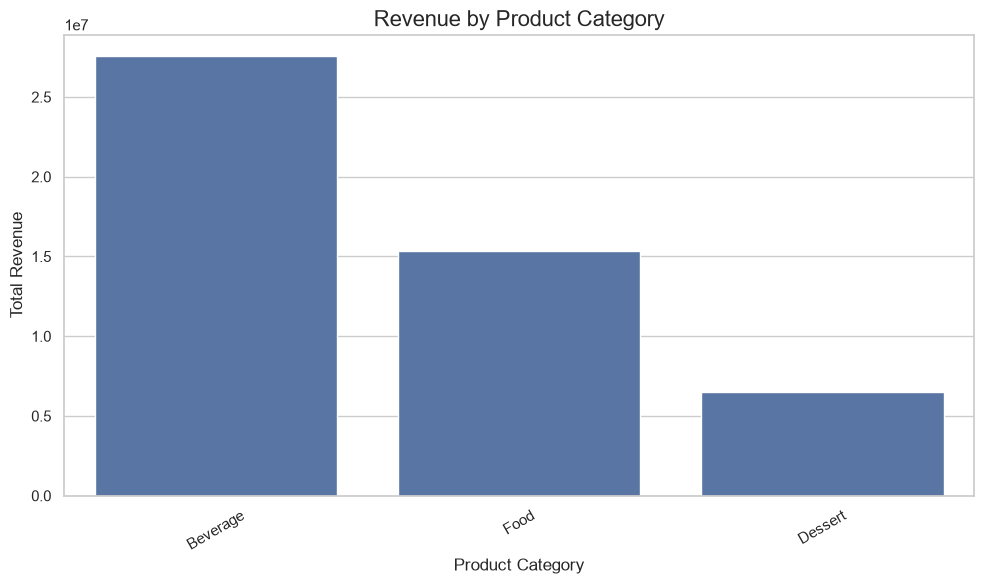

In [20]:
category_performance = (
    product_sales.groupby("category")
    .agg(
        total_revenue=("net_sales", "sum"),
        total_units=("quantity", "sum"),
        total_profit=("profit_amount", "sum")
    )
    .reset_index()
    .sort_values("total_revenue", ascending=False)
)

display(category_performance)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_performance,
    x="category",
    y="total_revenue"
)

plt.title("Revenue by Product Category", fontsize=16)
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [21]:
best_revenue_product = product_performance.loc[
    product_performance["total_revenue"].idxmax()
]

best_selling_product = product_performance.loc[
    product_performance["total_units"].idxmax()
]

best_profit_product = product_performance.loc[
    product_performance["total_profit"].idxmax()
]

print("PRODUCT PERFORMANCE HIGHLIGHTS")
print("=" * 55)

print(
    f"Highest Revenue: {best_revenue_product['product_name']} "
    f"({best_revenue_product['total_revenue']:,.2f})"
)

print(
    f"Most Units Sold: {best_selling_product['product_name']} "
    f"({best_selling_product['total_units']:,})"
)

print(
    f"Highest Profit: {best_profit_product['product_name']} "
    f"({best_profit_product['total_profit']:,.2f})"
)

PRODUCT PERFORMANCE HIGHLIGHTS
Highest Revenue: Beef Burger (4,209,523.50)
Most Units Sold: Cappuccino (22,606)
Highest Profit: Mocha (1,993,586.00)


In [22]:
# Merge sales data with customer dimension

customer_sales = sales.merge(
    customers,
    on="customer_id",
    how="left"
)

print("Customer sales dataset created.")
print("Records:", f"{len(customer_sales):,}")

customer_sales.head()

Customer sales dataset created.
Records: 122,318


,sales_id,order_id,date_id,store_id,customer_id,product_id,promotion_id,quantity,unit_price,discount_amount,...,month_name,day_name,is_weekend,is_holiday,season,signup_date,customer_segment,age_group,loyalty_member,acquisition_channel
0,SAL00000001,ORD00000001,20250101,ST001,CUS00522,PRD001,PROMO007,3,120.0,36.0,...,January,Wednesday,False,True,Winter,2023-05-31,New,45-54,False,Social Media
1,SAL00000002,ORD00000002,20250101,ST001,CUS00094,PRD001,PROMO007,2,120.0,24.0,...,January,Wednesday,False,True,Winter,2024-05-30,Premium,55+,False,Website
2,SAL00000003,ORD00000003,20250101,ST001,CUS00613,PRD001,PROMO007,1,120.0,12.0,...,January,Wednesday,False,True,Winter,2022-05-04,New,45-54,False,Mobile App
3,SAL00000004,ORD00000004,20250101,ST001,CUS00556,PRD001,PROMO007,1,120.0,12.0,...,January,Wednesday,False,True,Winter,2023-12-22,Premium,55+,True,Referral
4,SAL00000005,ORD00000005,20250101,ST001,CUS00026,PRD001,PROMO007,4,120.0,48.0,...,January,Wednesday,False,True,Winter,2022-08-17,Regular,25-34,False,Referral


In [23]:
segment_performance = (
    customer_sales.groupby("customer_segment")
    .agg(
        total_revenue=("net_sales", "sum"),
        total_orders=("order_id", "nunique"),
        total_units=("quantity", "sum"),
        unique_customers=("customer_id", "nunique"),
        total_profit=("profit_amount", "sum")
    )
    .reset_index()
    .sort_values("total_revenue", ascending=False)
)

display(segment_performance)

,customer_segment,total_revenue,total_orders,total_units,unique_customers,total_profit
3,Regular,21498177.8,53415,129540,437,11104687.8
1,Occasional,15218170.1,37635,91357,307,7853185.1
2,Premium,7424605.3,18272,44387,150,3826065.3
0,New,5243664.7,12996,31379,106,2702074.7


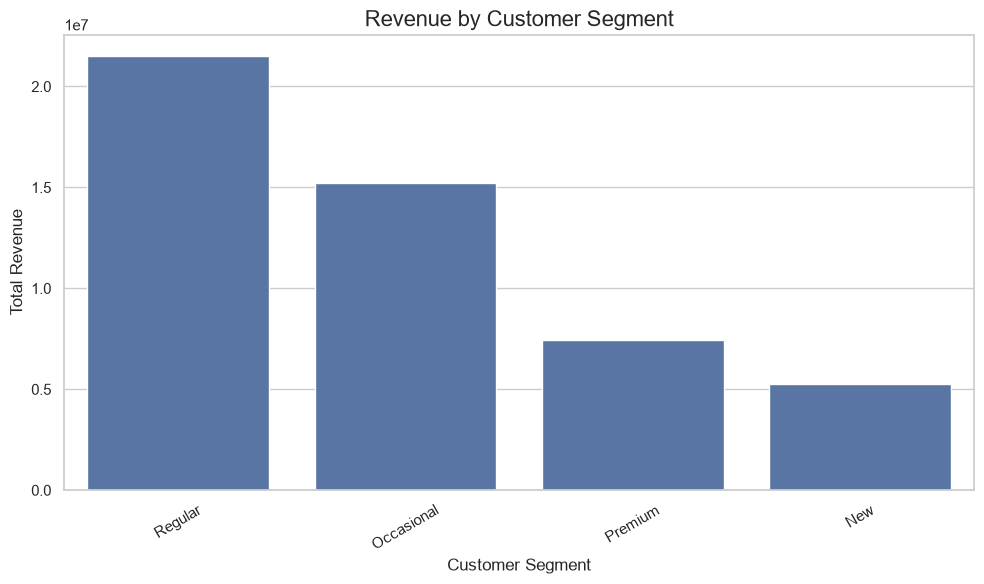

In [24]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=segment_performance,
    x="customer_segment",
    y="total_revenue"
)

plt.title("Revenue by Customer Segment", fontsize=16)
plt.xlabel("Customer Segment")
plt.ylabel("Total Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [25]:
channel_performance = (
    customer_sales.groupby("acquisition_channel")
    .agg(
        total_revenue=("net_sales", "sum"),
        unique_customers=("customer_id", "nunique"),
        total_orders=("order_id", "nunique"),
        total_profit=("profit_amount", "sum")
    )
    .reset_index()
    .sort_values("total_revenue", ascending=False)
)

display(channel_performance)

,acquisition_channel,total_revenue,unique_customers,total_orders,total_profit
1,Referral,10361984.1,212,25639,5343474.1
4,Website,10024333.9,202,24826,5175038.9
3,Walk-in,9986592.0,200,24575,5153227.0
0,Mobile App,9825513.0,199,24334,5068093.0
2,Social Media,9186194.9,187,22944,4746179.9


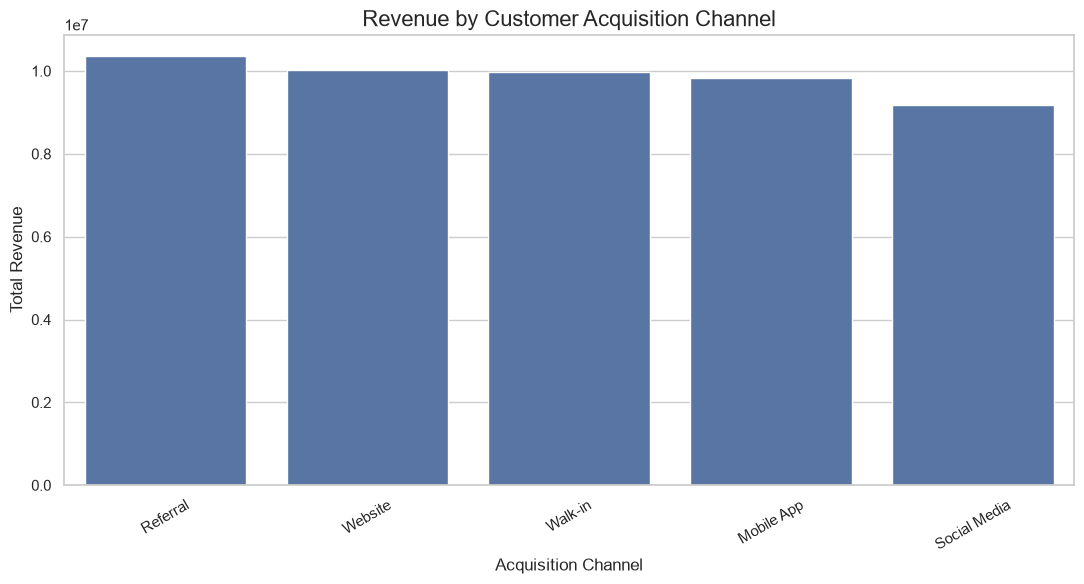

In [26]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=channel_performance,
    x="acquisition_channel",
    y="total_revenue"
)

plt.title("Revenue by Customer Acquisition Channel", fontsize=16)
plt.xlabel("Acquisition Channel")
plt.ylabel("Total Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [27]:
age_performance = (
    customer_sales.groupby("age_group")
    .agg(
        total_revenue=("net_sales", "sum"),
        unique_customers=("customer_id", "nunique"),
        total_orders=("order_id", "nunique"),
        total_units=("quantity", "sum")
    )
    .reset_index()
    .sort_values("total_revenue", ascending=False)
)

display(age_performance)

,age_group,total_revenue,unique_customers,total_orders,total_units
4,55+,11131717.0,224,27547,66720
3,45-54,10807536.7,219,26870,65022
1,25-34,9689062.7,196,23993,58177
2,35-44,9497208.3,192,23455,57029
0,18-24,8259093.2,169,20453,49715


In [28]:
customer_performance = (
    customer_sales.groupby("customer_id")
    .agg(
        total_revenue=("net_sales", "sum"),
        total_orders=("order_id", "nunique"),
        total_units=("quantity", "sum"),
        total_profit=("profit_amount", "sum")
    )
    .reset_index()
    .sort_values("total_revenue", ascending=False)
)

print("TOP 10 CUSTOMERS BY REVENUE")
print("=" * 55)

display(customer_performance.head(10))

TOP 10 CUSTOMERS BY REVENUE


,customer_id,total_revenue,total_orders,total_units,total_profit
66,CUS00067,69676.2,144,391,35251.2
69,CUS00070,68787.3,154,398,34777.3
739,CUS00740,65416.0,157,372,33026.0
108,CUS00109,64217.9,161,384,33162.9
528,CUS00529,64181.7,140,354,32106.7
884,CUS00885,63359.3,145,363,32374.3
583,CUS00584,63230.9,146,376,32530.9
751,CUS00752,63203.6,153,392,33003.6
665,CUS00666,62750.9,146,364,32190.9
988,CUS00989,62003.1,137,344,31238.1


In [29]:
best_segment = segment_performance.loc[
    segment_performance["total_revenue"].idxmax()
]

best_channel = channel_performance.loc[
    channel_performance["total_revenue"].idxmax()
]

best_age_group = age_performance.loc[
    age_performance["total_revenue"].idxmax()
]

print("CUSTOMER BEHAVIOR HIGHLIGHTS")
print("=" * 55)

print(
    f"Top Customer Segment: {best_segment['customer_segment']} "
    f"({best_segment['total_revenue']:,.2f} revenue)"
)

print(
    f"Top Acquisition Channel: {best_channel['acquisition_channel']} "
    f"({best_channel['total_revenue']:,.2f} revenue)"
)

print(
    f"Top Age Group: {best_age_group['age_group']} "
    f"({best_age_group['total_revenue']:,.2f} revenue)"
)

CUSTOMER BEHAVIOR HIGHLIGHTS
Top Customer Segment: Regular (21,498,177.80 revenue)
Top Acquisition Channel: Referral (10,361,984.10 revenue)
Top Age Group: 55+ (11,131,717.00 revenue)


In [30]:
# Merge inventory with store and product information

inventory_analysis = (
    inventory
    .merge(
        stores[["store_id", "city"]],
        on="store_id",
        how="left"
    )
    .merge(
        products[["product_id", "product_name", "category"]],
        on="product_id",
        how="left"
    )
)

print("Inventory analysis dataset created.")
print("Records:", f"{len(inventory_analysis):,}")

inventory_analysis.head()

Inventory analysis dataset created.
Records: 9,000


,inventory_id,date_id,store_id,product_id,opening_stock,received_qty,prepared_qty,sold_qty,closing_stock,damaged_qty,expired_qty,stockout_flag,city,product_name,category
0,INV00000001,20250101,ST001,PRD001,30,28,51,48,61,0,0,False,Dhaka,Americano,Beverage
1,INV00000002,20250102,ST001,PRD001,61,46,61,45,123,0,0,False,Dhaka,Americano,Beverage
2,INV00000003,20250103,ST001,PRD001,123,52,78,77,176,0,0,False,Dhaka,Americano,Beverage
3,INV00000004,20250104,ST001,PRD001,176,55,86,92,225,0,0,False,Dhaka,Americano,Beverage
4,INV00000005,20250105,ST001,PRD001,225,43,72,75,265,0,0,False,Dhaka,Americano,Beverage


In [36]:
inventory_kpis = pd.DataFrame({
    "KPI": [
        "Total Inventory Records",
        "Total Opening Stock",
        "Total Received Quantity",
        "Total Prepared Quantity",
        "Total Sold Quantity",
        "Total Closing Stock"
    ],
    "Value": [
        len(inventory_analysis),
        inventory_analysis["opening_stock"].sum(),
        inventory_analysis["received_qty"].sum(),
        inventory_analysis["prepared_qty"].sum(),
        inventory_analysis["sold_qty"].sum(),
        inventory_analysis["closing_stock"].sum()
    ]
})

display(inventory_kpis)

,KPI,Value
0,Total Inventory Records,9000
1,Total Opening Stock,12310086
2,Total Received Quantity,252035
3,Total Prepared Quantity,319439
4,Total Sold Quantity,296663
5,Total Closing Stock,12584897


In [32]:
product_inventory = (
    inventory_analysis.groupby(
        ["product_name", "category"]
    )
    .agg(
        average_closing_stock=("closing_stock", "mean"),
        total_closing_stock=("closing_stock", "sum"),
        total_sold=("sold_qty", "sum")
    )
    .reset_index()
    .sort_values("average_closing_stock", ascending=False)
)

display(product_inventory)

,product_name,category,average_closing_stock,total_closing_stock,total_sold
18,Mocha,Beverage,2130.515556,958732,22308
3,Cappuccino,Beverage,2107.266667,948270,22606
11,Espresso,Beverage,2107.251111,948263,22394
0,Americano,Beverage,2085.231111,938354,22533
15,Latte,Beverage,2046.515556,920932,21820
13,Iced Coffee,Beverage,1712.497778,770624,18106
14,Iced Latte,Beverage,1679.533333,755790,17748
16,Lemonade,Beverage,1655.177778,744830,18525
1,Beef Burger,Food,1334.562222,600553,13698
12,French Fries,Food,1319.855556,593935,13808


,city,total_closing_stock,total_sold,total_received
0,Chattogram,2364306,55357,47288
1,Dhaka,3030758,71927,61274
2,Khulna,2346789,55222,46763
3,Rajshahi,3052990,72734,61410
4,Sylhet,1790054,41423,35300


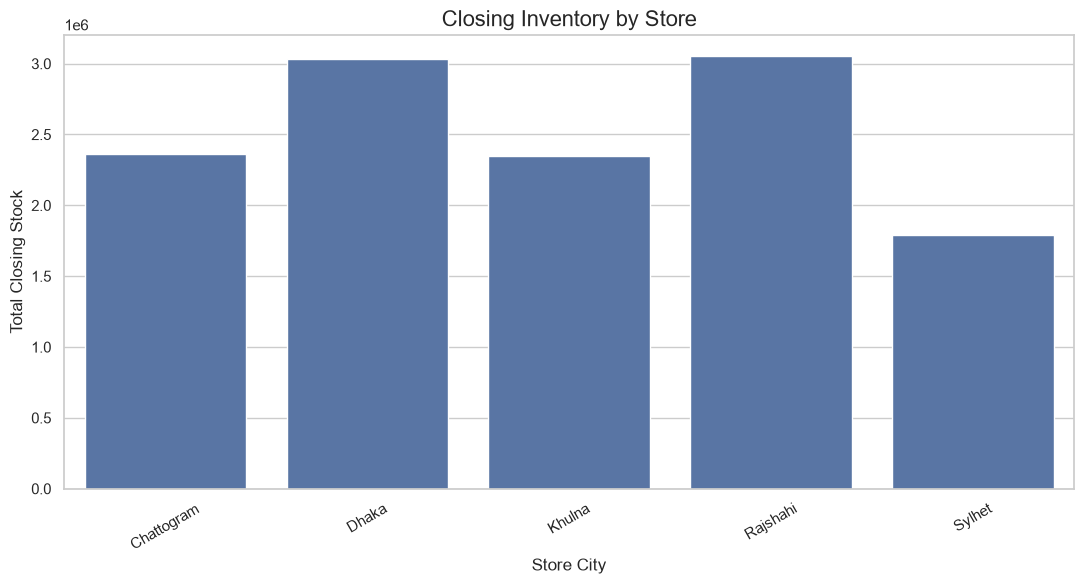

In [33]:
store_inventory = (
    inventory_analysis.groupby("city")
    .agg(
        total_closing_stock=("closing_stock", "sum"),
        total_sold=("sold_qty", "sum"),
        total_received=("received_qty", "sum")
    )
    .reset_index()
)

display(store_inventory)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=store_inventory,
    x="city",
    y="total_closing_stock"
)

plt.title("Closing Inventory by Store", fontsize=16)
plt.xlabel("Store City")
plt.ylabel("Total Closing Stock")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [37]:
preparation_analysis = (
    inventory_analysis
    .groupby(["product_name", "category"])
    .agg(
        total_prepared=("prepared_qty", "sum"),
        total_sold=("sold_qty", "sum")
    )
    .reset_index()
)

preparation_analysis["preparation_surplus"] = (
    preparation_analysis["total_prepared"]
    - preparation_analysis["total_sold"]
)

display(
    preparation_analysis.sort_values(
        "preparation_surplus",
        ascending=False
    )
)

,product_name,category,total_prepared,total_sold,preparation_surplus
15,Latte,Beverage,23695,21820,1875
3,Cappuccino,Beverage,24415,22606,1809
11,Espresso,Beverage,24127,22394,1733
18,Mocha,Beverage,23932,22308,1624
0,Americano,Beverage,24111,22533,1578
14,Iced Latte,Beverage,19178,17748,1430
13,Iced Coffee,Beverage,19345,18106,1239
16,Lemonade,Beverage,19730,18525,1205
12,French Fries,Food,14879,13808,1071
1,Beef Burger,Food,14752,13698,1054


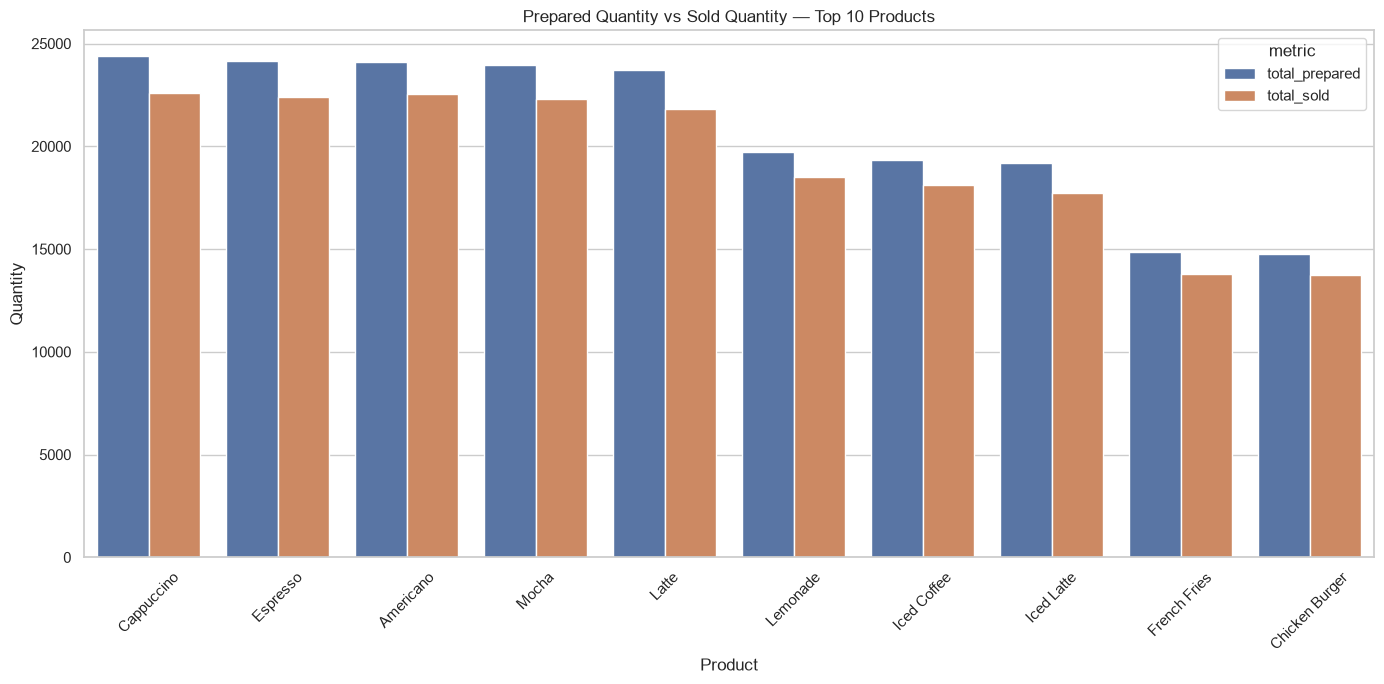

In [38]:
top_products = preparation_analysis.nlargest(
    10, "total_prepared"
)

comparison_data = top_products.melt(
    id_vars="product_name",
    value_vars=["total_prepared", "total_sold"],
    var_name="metric",
    value_name="quantity"
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=comparison_data,
    x="product_name",
    y="quantity",
    hue="metric"
)

plt.title("Prepared Quantity vs Sold Quantity — Top 10 Products")
plt.xlabel("Product")
plt.ylabel("Quantity")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [39]:
# Merge waste data with store and product information

waste_analysis = (
    waste
    .merge(
        stores[["store_id", "city"]],
        on="store_id",
        how="left"
    )
    .merge(
        products[["product_id", "product_name", "category", "unit_cost"]],
        on="product_id",
        how="left"
    )
)

print("Waste analysis dataset created.")
print("Records:", f"{len(waste_analysis):,}")

waste_analysis.head()

Waste analysis dataset created.
Records: 3,648


,waste_id,date_id,store_id,product_id,waste_reason_id,quantity_wasted,unit_cost_x,waste_cost,city,product_name,category,unit_cost_y
0,WST00000001,20250101,ST001,PRD003,Overproduction,2,70.0,140.0,Dhaka,Latte,Beverage,70
1,WST00000002,20250101,ST001,PRD008,Overproduction,2,55.0,110.0,Dhaka,Lemonade,Beverage,55
2,WST00000003,20250101,ST001,PRD010,Overproduction,2,100.0,200.0,Dhaka,Chocolate Shake,Beverage,100
3,WST00000004,20250101,ST001,PRD011,Overproduction,3,140.0,420.0,Dhaka,Chicken Sandwich,Food,140
4,WST00000005,20250101,ST001,PRD013,Overproduction,7,160.0,1120.0,Dhaka,Chicken Burger,Food,160


In [40]:
print("WASTE COLUMNS")
print(waste.columns.tolist())

WASTE COLUMNS
['waste_id', 'date_id', 'store_id', 'product_id', 'waste_reason_id', 'quantity_wasted', 'unit_cost', 'waste_cost']


In [42]:
waste_kpis = pd.DataFrame({
    "KPI": [
        "Total Waste Records",
        "Total Waste Quantity",
        "Total Waste Cost",
        "Average Waste per Record"
    ],
    "Value": [
        len(waste_analysis),
        waste_analysis["quantity_wasted"].sum(),
        waste_analysis["waste_cost"].sum(),
        waste_analysis["quantity_wasted"].mean()
    ]
})

display(
    waste_kpis.style.format({"Value": "{:,.2f}"})
)

,KPI,Value
0,Total Waste Records,"3,648.00"
1,Total Waste Quantity,"11,687.00"
2,Total Waste Cost,"951,885.00"
3,Average Waste per Record,3.20


In [43]:
waste_by_product = (
    waste_analysis.groupby("product_name")
    .agg(
        total_waste=("quantity_wasted", "sum"),
        total_waste_cost=("waste_cost", "sum")
    )
    .reset_index()
    .sort_values("total_waste", ascending=False)
)

display(waste_by_product)

,product_name,total_waste,total_waste_cost
15,Latte,939,65730.0
11,Espresso,902,31570.0
3,Cappuccino,881,57265.0
0,Americano,816,36720.0
18,Mocha,783,62640.0
14,Iced Latte,739,59120.0
13,Iced Coffee,665,46550.0
16,Lemonade,576,31680.0
12,French Fries,539,35035.0
1,Beef Burger,539,97020.0


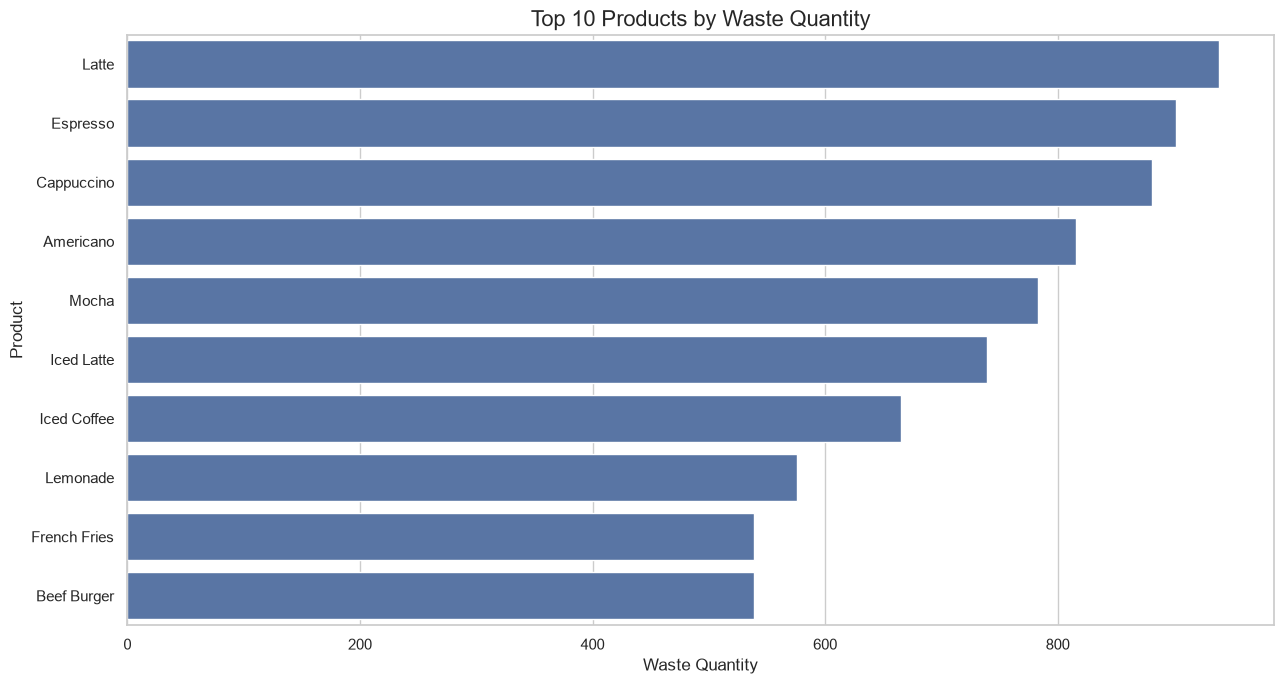

In [44]:
top_waste_products = waste_by_product.head(10)

plt.figure(figsize=(13, 7))

sns.barplot(
    data=top_waste_products,
    x="total_waste",
    y="product_name"
)

plt.title("Top 10 Products by Waste Quantity", fontsize=16)
plt.xlabel("Waste Quantity")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [45]:
waste_by_store = (
    waste_analysis.groupby("city")
    .agg(
        total_waste=("quantity_wasted", "sum"),
        total_waste_cost=("waste_cost", "sum")
    )
    .reset_index()
    .sort_values("total_waste", ascending=False)
)

display(waste_by_store)

,city,total_waste,total_waste_cost
1,Dhaka,2821,226215.0
3,Rajshahi,2776,227265.0
0,Chattogram,2297,185025.0
2,Khulna,2123,176580.0
4,Sylhet,1670,136800.0


In [46]:
waste_by_reason = (
    waste_analysis.groupby("waste_reason_id")
    .agg(
        total_waste=("quantity_wasted", "sum"),
        total_waste_cost=("waste_cost", "sum"),
        waste_records=("waste_id", "count")
    )
    .reset_index()
    .sort_values("total_waste", ascending=False)
)

display(waste_by_reason)

,waste_reason_id,total_waste,total_waste_cost,waste_records
2,Overproduction,10981,899430.0,3176
1,Expired,578,38875.0,344
0,Damaged,57,5915.0,57
3,Preparation Error,39,4160.0,39
4,Quality Issue,32,3505.0,32


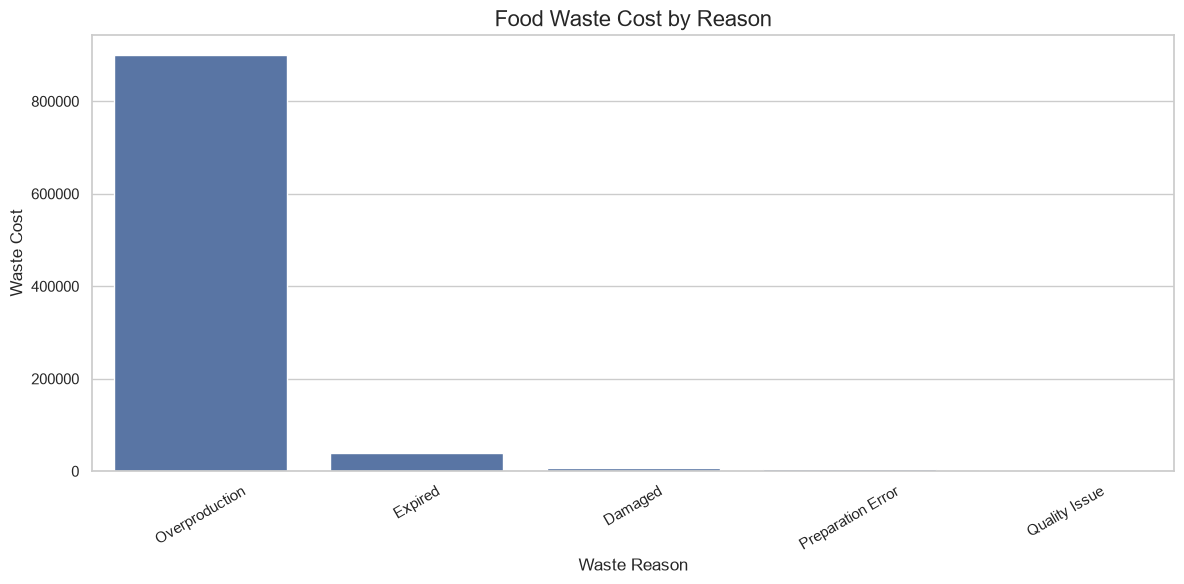

In [47]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=waste_by_reason,
    x="waste_reason_id",
    y="total_waste_cost"
)

plt.title("Food Waste Cost by Reason", fontsize=16)
plt.xlabel("Waste Reason")
plt.ylabel("Waste Cost")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [48]:
total_prepared = inventory["prepared_qty"].sum()
total_waste = waste["quantity_wasted"].sum()

waste_rate = (
    total_waste / total_prepared * 100
    if total_prepared > 0 else 0
)

print(f"Total Prepared Quantity: {total_prepared:,.2f}")
print(f"Total Waste Quantity: {total_waste:,.2f}")
print(f"Overall Waste Rate: {waste_rate:.2f}%")

Total Prepared Quantity: 319,439.00
Total Waste Quantity: 11,687.00
Overall Waste Rate: 3.66%


In [49]:
# Consolidated business insights

print("=" * 65)
print("SMARTSERVE — BUSINESS INSIGHTS")
print("=" * 65)

# 1. Overall sales
print("\n1. OVERALL SALES PERFORMANCE")
print("-" * 45)
print(f"Revenue: {total_revenue:,.2f}")
print(f"Profit: {total_profit:,.2f}")
print(f"Profit Margin: {profit_margin:.2f}%")
print(f"Average Order Value: {average_order_value:,.2f}")

# 2. Store performance
print("\n2. STORE PERFORMANCE")
print("-" * 45)
print(
    f"Top Revenue Store: {best_revenue_store['city']} "
    f"({best_revenue_store['total_revenue']:,.2f})"
)
print(
    f"Top Profit Store: {best_profit_store['city']} "
    f"({best_profit_store['total_profit']:,.2f})"
)

# 3. Product performance
print("\n3. PRODUCT PERFORMANCE")
print("-" * 45)
print(
    f"Top Revenue Product: {best_revenue_product['product_name']}"
)
print(
    f"Best-Selling Product: {best_selling_product['product_name']}"
)
print(
    f"Top Profit Product: {best_profit_product['product_name']}"
)

# 4. Customer behavior
print("\n4. CUSTOMER BEHAVIOR")
print("-" * 45)
print(f"Top Customer Segment: {best_segment['customer_segment']}")
print(f"Top Acquisition Channel: {best_channel['acquisition_channel']}")
print(f"Top Age Group: {best_age_group['age_group']}")

# 5. Food waste
print("\n5. FOOD WASTE")
print("-" * 45)
print(f"Total Waste Quantity: {total_waste:,.2f}")
print(f"Total Waste Cost: {waste['waste_cost'].sum():,.2f}")
print(f"Overall Waste Rate: {waste_rate:.2f}%")

print("\n" + "=" * 65)
print("BUSINESS INSIGHTS SUMMARY COMPLETED")
print("=" * 65)

SMARTSERVE — BUSINESS INSIGHTS

1. OVERALL SALES PERFORMANCE
---------------------------------------------
Revenue: 49,384,617.90
Profit: 25,486,012.90
Profit Margin: 51.61%
Average Order Value: 403.74

2. STORE PERFORMANCE
---------------------------------------------
Top Revenue Store: Rajshahi (12,131,339.10)
Top Profit Store: Rajshahi (6,255,264.10)

3. PRODUCT PERFORMANCE
---------------------------------------------
Top Revenue Product: Beef Burger
Best-Selling Product: Cappuccino
Top Profit Product: Mocha

4. CUSTOMER BEHAVIOR
---------------------------------------------
Top Customer Segment: Regular
Top Acquisition Channel: Referral
Top Age Group: 55+

5. FOOD WASTE
---------------------------------------------
Total Waste Quantity: 11,687.00
Total Waste Cost: 951,885.00
Overall Waste Rate: 3.66%

BUSINESS INSIGHTS SUMMARY COMPLETED


# Business Insights and Recommendations

## 1. Sales and Revenue Optimization
- Monitor daily and weekly revenue patterns.
- Identify high-performing sales periods.
- Develop targeted promotions during weaker sales periods.
- Track Average Order Value to evaluate upselling opportunities.

## 2. Store Performance Optimization
- Benchmark stores using revenue, profit, and profit margin.
- Investigate operational differences between high- and low-performing stores.
- Allocate staff and inventory according to store-level demand.

## 3. Product Portfolio Optimization
- Prioritize products with strong revenue and profitability.
- Investigate products with low sales or weak profit contribution.
- Use product-level demand patterns to improve preparation planning.

## 4. Customer Strategy
- Develop targeted campaigns for valuable customer segments.
- Evaluate acquisition channels using customer count and revenue.
- Encourage repeat purchases through loyalty initiatives.

## 5. Inventory and Preparation Optimization
- Align preparation quantities with expected demand.
- Monitor inventory levels to identify potential stockout risks.
- Investigate products with consistently high preparation surplus.

## 6. Food Waste Reduction
- Identify products, stores, and reasons contributing most to waste.
- Improve demand forecasting and preparation planning.
- Monitor waste quantity, waste cost, and waste rate.

## 7. Future Machine Learning Opportunities
- Develop product-level demand forecasting models.
- Predict daily demand for each store and product.
- Use predictions to recommend preparation quantities.
- Evaluate models using MAE, RMSE, WAPE, and forecast bias.

## Conclusion

The exploratory analysis establishes a baseline understanding of
SmartServe's synthetic sales and operational data.

The next stages will transform these findings into data-driven
solutions using SQL, Excel, Power BI, and Machine Learning.